## 一、安装依赖
```
uv add sqlalchemy[asyncio], asyncpg
```

## 二、基础环境准备

### 2.1 初始化数据库连接池 app.infra.database.py

- `sqlalchemy[asyncio]` - 异步数据库 ORM
- `asyncpg` - 异步数据库驱动

In [20]:
from sqlalchemy.ext.asyncio import (
    create_async_engine, # 1. 创建异步引擎
    async_sessionmaker,  # 2. 创建异步 Session 工厂
    AsyncSession,        # 3. 创建异步 Session
)
from sqlalchemy import text

from app.core.config import settings
from app.core.logging import get_logger
logger = get_logger(__name__)

# 1. 数据库连接地址
if not settings.db or not settings.db.url:
    raise RuntimeError("db.url未配置，初始化数据库失败！")
DATABASE_URL = settings.db.url

# 2. 创建异步数据库引擎
engine = create_async_engine(
    DATABASE_URL,
    echo=settings.db.echo,                  # 是否打印SQL语句
    pool_size=settings.db.pool_size,        # 连接池中长期保留的连接数
    max_overflow=settings.db.max_overflow,  # 连接池满后，允许临时创建的额外连接数
    pool_recycle=settings.db.pool_recycle,  # 连接存活超过该时间后，在下次取出时重新创建
    pool_pre_ping=True,                     # 从连接池取出连接时，先检查连接是否有效
)

# 3. 创建异步 Session 工厂
AsyncSessionFactory = async_sessionmaker(
    bind=engine,
    autoflush=False,        # 关闭自动刷新，提升批量操作性能
    expire_on_commit=False, # commit 后保留 ORM 对象中的属性值
)

# 4. 获取session的工具
async def get_db() -> AsyncSession | None:
    """ 为每个 FastAPI 请求创建独立的 AsyncSession，适用于依赖注入。后续作为参数使用 db: AsyncSession = Depends(get_db)"""
    async with AsyncSessionFactory() as session:
        yield session

# 5. 释放数据库连接池
async def close_database() -> None:
    """ 关闭数据库引擎并释放连接池中的连接。应在应用关闭时调用。"""
    await engine.dispose()
    logger.info("数据库连接池已关闭~")

# 6. 初始化数据库连接池
async def check_database() -> None:
    async with engine.connect() as connection:
        await connection.execute(text("SELECT 1"))
    logger.info("数据库连接池初始化成功~✅️")

### 2.2 生命周期管理 app.main.py

在 FastAPI 中，使用 `lifespan` 事件来统一管理连接池的创建与销毁，避免连接泄漏

In [21]:
from fastapi import FastAPI
from contextlib import asynccontextmanager                     # 数据库连接池管理
@asynccontextmanager
async def lifespan(app: FastAPI):
    logger.info(f"【{settings.app.name}】应用启动中...")
    # from app.infra.database import check_database, close_database
    try:
        # 初始化
        await check_database()
        yield
    finally:
        # 关闭
        logger.info("应用关闭中... ")
        await close_database()

app = FastAPI(lifespan=lifespan)

### 2.3 结合 FastAPI 的依赖注入 app.main.py

In [22]:
from fastapi import Depends
@app.post("/products/")
async def create_product_api(db: AsyncSession = Depends(get_db)):
    # 业务逻辑...
    pass

### 三、Models

### 根据 DDL 建表语句创建 Models

In [23]:
from datetime import datetime
from sqlalchemy import String, Numeric, Boolean, DateTime, Index, func
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column

"""Base class for all mapped classes."""
class Base(DeclarativeBase):
    def __repr__(self) -> str:
        """通用的repr函数，用于控制台输出对象信息"""
        # 获取当前类名
        cls_name = self.__class__.__name__
        # 保存属性 key（属性）：value（值）
        attrs = {}
        # 遍历对象的所有属性
        for key, val in vars(self).items():
            # 过滤掉 SQLAlchemy 内部以 _ 开头的私有属性
            if key.startswith("_"):
                continue
            # 时间类型格式化
            if isinstance(val, datetime):
                attrs[key] = val.strftime("%Y-%m-%d %H:%M:%S")
            else:
                attrs[key] = val
        # 拼成最终字符串，如：Product({'id': 1, 'name': '重疾险A', ...})
        return f"{cls_name}({attrs})"

class Product(Base):
    __tablename__ = "product"

    id: Mapped[int] = mapped_column(primary_key=True, autoincrement=True)
    name: Mapped[str] = mapped_column(String(100), nullable=False, comment="产品名称")
    category: Mapped[str] = mapped_column(String(50), nullable=False)
    price: Mapped[float] = mapped_column(Numeric(10, 2), nullable=False)
    created_at: Mapped[datetime] = mapped_column(DateTime(timezone=True), nullable=False, server_default=func.now(), comment="创建时间")
    updated_at: Mapped[datetime] = mapped_column(DateTime(timezone=True), nullable=False, server_default=func.now(), onupdate=func.now(), comment="最后更新时间")

    __table_args__ = (
        Index("ix_product_category", "category"),
        Index("idx_category_price", "category", "price"),  # 联合索引
    )


"""sql
create table product
(
    id         serial primary key,
    name       varchar(100)                           not null,
    category   varchar(50)                            not null,
    price      numeric(10, 2)                         not null,
    created_at timestamp with time zone default now() not null,
    updated_at timestamp with time zone default now() not null
);

comment on column product.name is '产品名称';
comment on column product.created_at is '创建时间';
comment on column product.updated_at is '最后更新时间';

create index idx_category_price on product (category, price);
create index ix_product_category on product (category);
"""
print()

In [24]:
p = Product(name="重疾险A", category="重疾险", price=10000.00)
print(p)

Product({'name': '重疾险A', 'category': '重疾险', 'price': 10000.0})


In [25]:
# 开发/测试环境：一次性建表（幂等，表已存在则跳过）
async with engine.begin() as conn:
    await conn.run_sync(Base.metadata.create_all) # 只能新建表，不会修改已有表结构（加字段、改类型都不生效）

### 四、Repository

### 4.1 核心方法速查表

| 方法 | 是否需 await | 作用与说明 |
| :--- | :--- | :--- |
| `session.add(obj)` | ❌ 否 | 纯内存操作，将对象标记为“待插入” |
| `await session.execute(stmt)` | ✅ 是 | 发送 SQL 到数据库执行（含 select/update/delete） |
| `await session.commit()` | ✅ 是 | 提交事务，永久落盘，释放锁 |
| `await session.refresh(obj)` | ✅ 是 | 从数据库重新查询对象最新状态（获取自增 ID 等） |
| `await session.rollback()` | ✅ 是 | 发生异常时撤销当前事务所有未提交变更 |



### 4.2 标准 CRUD 语法

| 操作类型 | 核心方法/语法                          | 适用场景说明 |
| :--- |:---------------------------------| :--- |
| **Create (增)** | `session.add(obj)`               | 新增单条数据，将对象加入会话 |
| | `session.add_all([obj1, obj2])`  | 批量新增多条数据 |
| **Read (查)** | `session.get(Model, id)`         | **最快**，仅支持根据主键查询单条 |
| | `session.execute(select(Model))` | 构建复杂条件查询的基础语句 |
| **Update (改)** | 直接修改对象属性 + `commit()`            | ORM 自动检测变更并生成 UPDATE 语句 |
| **Delete (删)** | `session.delete(obj)`            | 根据对象实例删除数据 |



#### 创建（Create）

In [39]:
# 单条
async def create_one(db: AsyncSession, data: dict) -> Product:
    obj = Product(**data)
    db.add(obj)             # 1. 添加到会话
    await db.commit()       # 2. 提交事务
    await db.refresh(obj)   # 3. 刷新数据库生成字段（如 created_at）
    return obj

# 多条
async def create_many(db: AsyncSession, data: list[dict]) -> list[Product]:
    objs = [Product(**_data) for _data in data]
    db.add_all(objs)         # 1. 添加到会话
    await db.commit()        # 2. 提交事务
    for obj in objs:         # 3. 遍历列表，逐个刷新数据库生成字段
        await db.refresh(obj)
    return objs

In [40]:
product_data = {"name": "百万医疗险", "category": "health", "price": 350.00}
async with AsyncSessionFactory() as session:
    await create_one(session, product_data)


In [41]:
products_data = [
    {"name": "意外险", "category": "accident", "price": 120.00},
    {"name": "定期寿险", "category": "life", "price": 2200.00},
    {"name": "少儿重疾险", "category": "critical_illness", "price": 3200.80},
    {"name": "高端医疗险", "category": "health", "price": 12000.00}
]
async with AsyncSessionFactory() as session:
    await create_many(session, products_data)

#### 查询（Read）

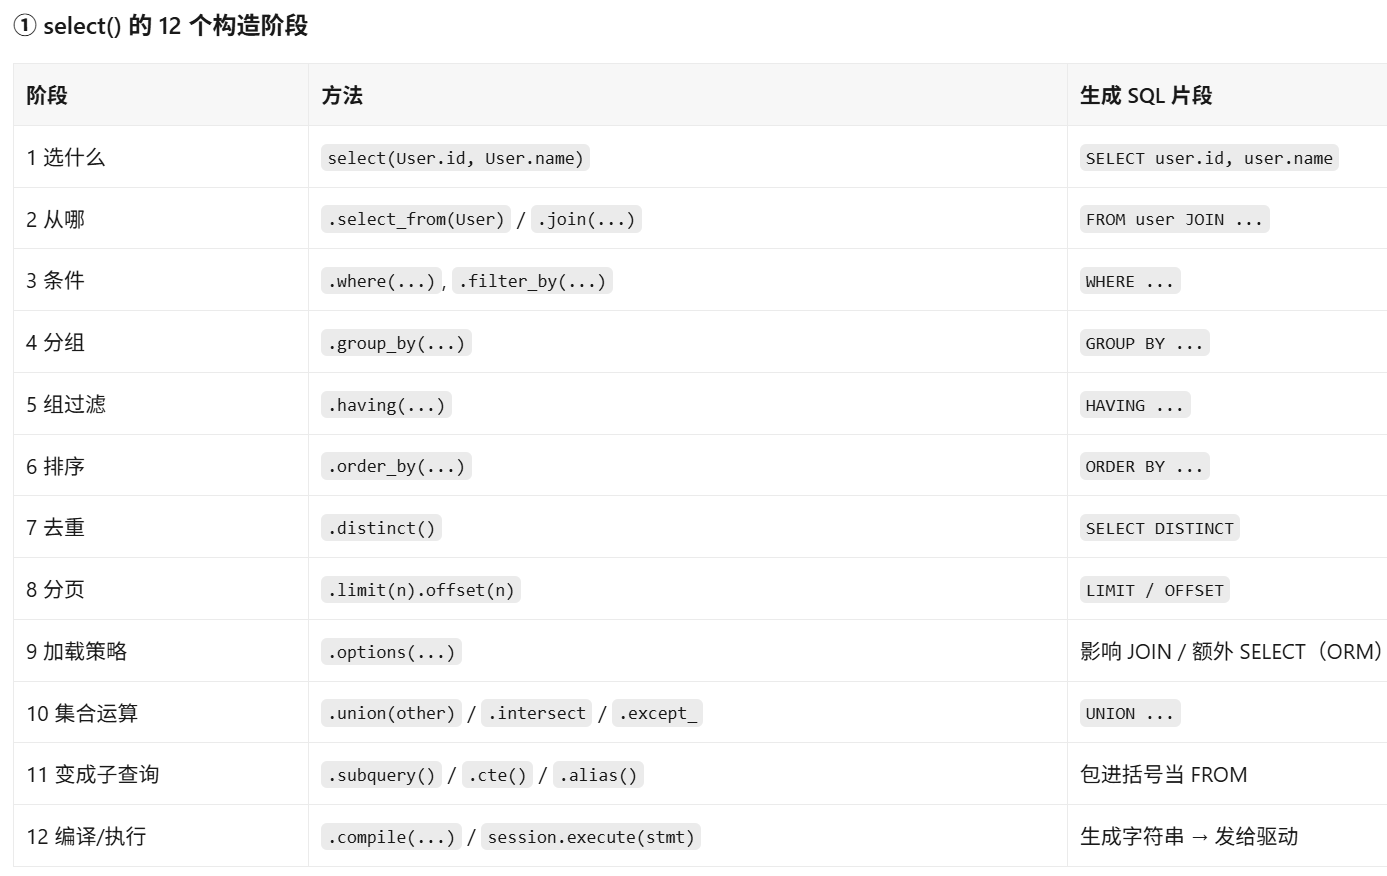

In [50]:
from sqlalchemy import select
stmt = select(Product).where(Product.category == "critical_illness", Product.price > 3000.00)
print(stmt)

SELECT product.id, product.name, product.category, product.price, product.created_at, product.updated_at 
FROM product 
WHERE product.category = :category_1 AND product.price > :price_1


In [42]:
from sqlalchemy import select

# 主键查询方式
async def get_product_by_id(db: AsyncSession, pid: int) -> Product:
    return await db.get(Product, pid)

# 标准查询语法
async def get_product_by_category(db: AsyncSession, category: str) -> list[Product]:
    query = select(Product).where(Product.category == category)
    result = await db.execute(query)
    # result.scalar_one_or_none() # 返回一个结果
    # result.scalars().all()      # 返回所有结果
    # result.scalars().first()    # 返回第一个结果
    return result.scalars().all()

In [43]:
async with AsyncSessionFactory() as session:
    product_by_id = await get_product_by_id(session, 1)
    print(product_by_id)
    product_by_category = await get_product_by_category(session, "critical_illness")
    print(product_by_category)

Product({'id': 1, 'price': Decimal('350.00'), 'updated_at': '2026-11-18 05:22:03', 'created_at': '2026-11-18 05:22:03', 'name': '百万医疗险', 'category': 'health'})
[Product({'id': 4, 'price': Decimal('3200.80'), 'updated_at': '2026-11-18 05:26:31', 'created_at': '2026-11-18 05:26:31', 'name': '少儿重疾险', 'category': 'critical_illness'}), Product({'id': 9, 'price': Decimal('3200.80'), 'updated_at': '2026-11-18 05:27:19', 'created_at': '2026-11-18 05:27:19', 'name': '少儿重疾险', 'category': 'critical_illness'}), Product({'id': 14, 'price': Decimal('3200.80'), 'updated_at': '2026-11-18 05:28:35', 'created_at': '2026-11-18 05:28:35', 'name': '少儿重疾险', 'category': 'critical_illness'})]


#### 更新（Update）

In [44]:
async def update_one(db: AsyncSession, pid: int, data: dict) -> Product:
    obj = await db.get(Product, pid)
    if not obj:
        return None
    for key, value in data.items():
        setattr(obj, key, value)
    db.add(obj)
    await db.commit()
    await db.refresh(obj)
    return obj

#### 删除（Delete）